# Galápagos islands from polygons

The [areas from polygons example](geodataframe.ipynb) shows how `from_geodataframe()`
turns a map into a `sars` dataset, and why the coordinate system matters. Its ten
counties are all of a size, though (the largest is less than four times the smallest),
so the curve it fits can't be trusted.

This notebook does the same over the range a species–area curve needs. The polygons
are 28 Galápagos islands from OpenStreetMap, from Onslow (0.02 km²) to Isabela
(4,700 km²). The plant species counts are Johnson and Raven's (1973), bundled with
`sars` as `load_gala()`. The two sources are joined by island name.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

import sars

## The polygons

`data/galapagos_islands.geojson` holds the outlines of the 28 islands, in longitude and
latitude. They come from OpenStreetMap, simplified to keep the file small (no island's
area moved by more than 0.75%). Each feature has the island's name as `load_gala()`
spells it, OpenStreetMap's own name for it, and the OpenStreetMap feature it came from.
Las Plazas is two islets, North and South Plaza, for which Johnson and Raven give one
figure (0.23 km²; the two polygons together come to 0.22), so its feature holds both.

In [2]:
islands = gpd.read_file("data/galapagos_islands.geojson")
islands.drop(columns="geometry").head(8)

,island,osm_name,osm
0,Baltra,Isla Baltra,relation/2129829
1,Bartolome,Isla Bartolomé,relation/13299590
2,Caldwell,Isla Caldwell,way/5113389
3,Champion,Isla Campeón,way/34201438
4,Coamano,Isla Caamaño,way/5113517
5,Daphne Major,Daphne Mayor,way/5113815
6,Daphne Minor,Daphne Menor,way/5113846
7,Darwin,Isla Darwin,way/551730596


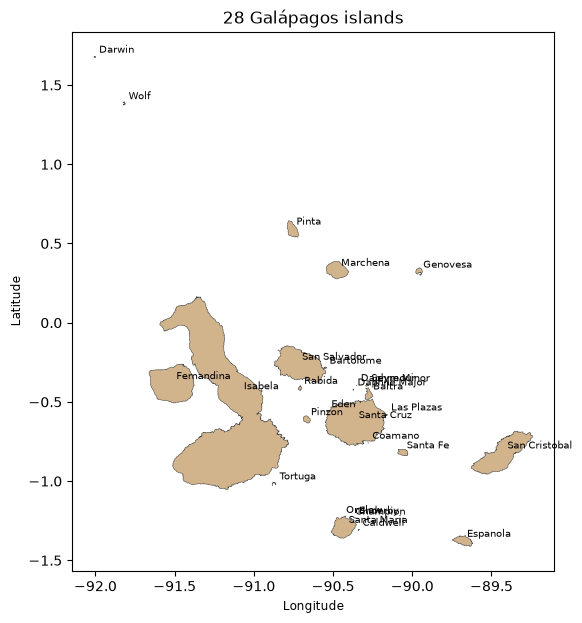

In [3]:
ax = islands.plot(color="tan", edgecolor="0.3", linewidth=0.4, figsize=(8, 7))
for name, point in zip(islands["island"], islands.representative_point(), strict=True):
    ax.annotate(name, (point.x, point.y), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="Longitude", ylabel="Latitude", title="28 Galápagos islands")
plt.show()

## Attaching the species counts

`load_gala()` names its islands as Johnson and Raven did, in English and without
accents. OpenStreetMap uses the Spanish names, and for three islands other names
altogether: Santa María is Floreana, San Salvador is Santiago, and Seymour is North
Seymour. The `island` column of the GeoJSON already holds `load_gala()`'s spelling, so
the join is on that column. It is checked, not assumed: `validate="one_to_one"` fails
if an island matches two rows, and the assertion fails if one matches none.

One more thing before joining. A GeoDataFrame has an `.area` attribute, the area of
each geometry in the units of its coordinates, and `load_gala()` has a column called
`area`. After the join, `sites.area` would be the geometry's area in square degrees,
not the published one. Renaming the column first avoids the mix-up.

In [4]:
gala = sars.load_gala().rename(columns={"area": "area_km2"})
sites = islands.merge(gala, on="island", how="left", validate="one_to_one")
assert sites["species"].notna().all() and len(sites) == 28
sorted(set(gala["island"]) - set(sites["island"]))

['Gardner1', 'Gardner2']

Two of `load_gala()`'s 30 islands are left out. There are two islands called Gardner,
one off Floreana and one off Española, and OpenStreetMap maps both. But `load_gala()`
calls them Gardner1 and Gardner2 and doesn't say which is which, so its rows can't be
paired with the polygons except by guessing from their areas.

## Areas from the polygons

The coordinates are in degrees, so the polygons are reprojected before their areas are
measured. EPSG:6933 is an equal-area projection that works anywhere on Earth. Near the
equator even Web Mercator barely distorts area, unlike at the latitude of the counties
example, but an equal-area projection is still the habit to keep.

In [5]:
data = sars.from_geodataframe(sites.to_crs("EPSG:6933"), species_col="species")
print(f"{len(data)} islands, {data['area'].min():.3f} to {data['area'].max():,.0f} km²")

28 islands, 0.019 to 4,702 km²


## How good are the computed areas?

In [6]:
compare = pd.DataFrame(
    {
        "island": sites["island"],
        "computed km²": data["area"].round(3),
        "published km²": sites["area_km2"],
    }
)
compare["computed / published"] = (compare["computed km²"] / compare["published km²"]).round(2)
compare.sort_values("computed / published")

,island,computed km²,published km²,computed / published
7,Darwin,0.630,2.33,0.27
27,Wolf,1.270,2.85,0.45
6,Daphne Minor,0.047,0.08,0.59
9,Enderby,0.115,0.18,0.64
12,Genovesa,13.808,17.35,0.80
3,Champion,0.092,0.10,0.92
14,Las Plazas,0.219,0.23,0.95
2,Caldwell,0.204,0.21,0.97
0,Baltra,25.180,25.09,1.00
25,Seymour,1.833,1.84,1.00


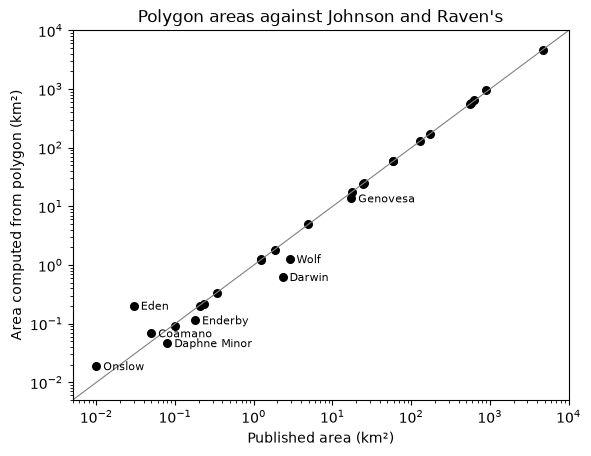

In [7]:
ax = compare.plot.scatter(x="published km²", y="computed km²", s=30, color="black", loglog=True)
lims = [0.005, 10_000]
ax.plot(lims, lims, color="grey", linewidth=0.8)
far_off = compare[(compare["computed / published"] - 1).abs() > 0.1]
for _, row in far_off.iterrows():
    ax.annotate(
        row["island"],
        (row["published km²"], row["computed km²"]),
        xytext=(5, -3),
        textcoords="offset points",
        fontsize=8,
    )
ax.set(
    xlim=lims,
    ylim=lims,
    xlabel="Published area (km²)",
    ylabel="Area computed from polygon (km²)",
    title="Polygon areas against Johnson and Raven's",
)
plt.show()

Eighteen of the 28 islands are within 5% of the published area, among them every island
over 10 km² except Genovesa and Santa Cruz.

The other ten are real disagreements between the sources. The published areas are given
to two decimal places, which limits how precisely a small island's ratio can be read
(Onslow's 0.01 km² could be anything from 0.005 to 0.015), but every one of the ten
falls outside its rounding interval. Some are far outside: Eden is 0.20 km² from the
polygon and 0.03 published, Darwin 0.63 against 2.33. Of the large islands, Santa Cruz
comes out 9% larger than published (984 km² against 904; recent figures put it near
986) and Genovesa 20% smaller.

This notebook can't say which source is right for each island. A modern coastline
traced from satellite imagery has the better claim than a 1970s figure, but an
OpenStreetMap outline is only as careful as whoever drew it, and an island's "area" can
be measured with or without a crater lake or a tidal reef. On a log scale none of this
moves a point far, as the next section shows.

## Fitting a model

Fit the power law with the computed areas, and again with the published ones.
`area_col` makes `from_geodataframe()` take the areas from a column instead of the
geometry.

In [8]:
published = sars.from_geodataframe(sites, species_col="species", area_col="area_km2")
fits = {
    "computed areas": sars.sar_power(data),
    "published areas": sars.sar_power(published),
}
pd.DataFrame(
    {name: {"c": f.params["c"], "z": f.params["z"], "R²": f.r_squared} for name, f in fits.items()}
).T.round(3)

,c,z,R²
computed areas,33.877,0.296,0.753
published areas,33.475,0.298,0.743


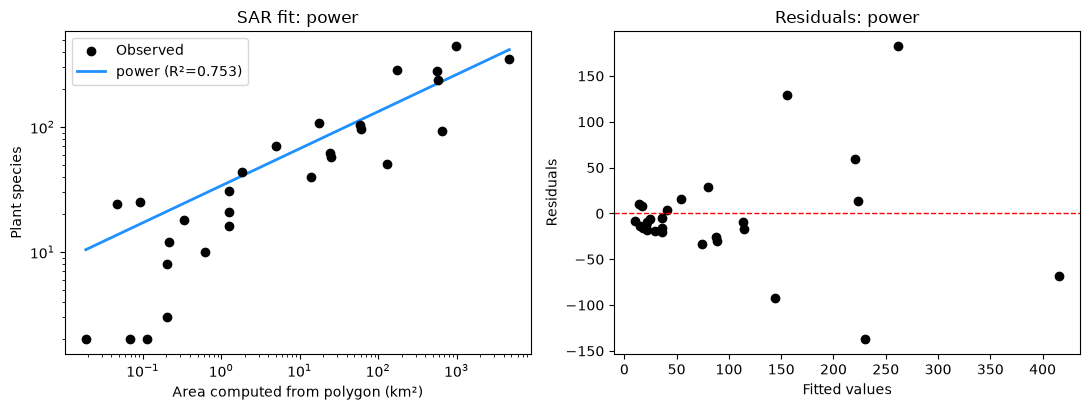

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sars.plot_fit(fits["computed areas"], ax=axes[0], log=True)
sars.plot_residuals(fits["computed areas"], ax=axes[1])
axes[0].set(xlabel="Area computed from polygon (km²)", ylabel="Plant species")
fig.tight_layout()
plt.show()

The two fits are almost the same curve: z is 0.296 with the computed areas and 0.298
with the published ones, and area explains about three quarters of the variation in
richness either way. Even an island whose two areas differ several-fold sits only a
little way along an axis that spans five orders of magnitude.

That is the difference from the counties example. There the areas spanned a factor of
four, and area explained under 40% of the variation. Here they span a factor of
250,000, and the curve is well determined.

## Comparing models

The 20 models of `sar_multi()` can be compared on these data as on any other.

In [10]:
multi = sars.sar_multi(data)
multi.summary[["model", "R2", "AICc", "delta_AICc", "weight"]].head(6).round(3)

,model,R2,AICc,delta_AICc,weight
0,koba,0.765,311.914,0.000,0.136
1,p1,0.787,311.916,0.001,0.136
2,chapman,0.783,312.359,0.445,0.109
3,weibull3,0.779,312.937,1.023,0.081
4,power,0.753,313.302,1.388,0.068
5,mmf,0.775,313.341,1.426,0.067


No model stands out. The leaders are within about two AICc units of one another, and
the power law is among them, so a model average is the natural summary (see the
[Galápagos plants example](galapagos.ipynb)).

## Sources

- **Polygons:** © OpenStreetMap contributors, available under the
  [Open Database License](https://www.openstreetmap.org/copyright). See
  `data/README.md` for how the file was made.
- **Species counts and published areas:** Johnson MP, Raven PH (1973). Species number
  and endemism: the Galápagos Archipelago revisited. *Science* 179(4076), 893–895,
  as in R `faraway`'s `gala` (`sars.load_gala()`).